In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.io import loadmat

In [2]:
# Project root directory
PROJECT_ROOT = r"C:\Users\medha\OneDrive\Documents\TrustSenseBMS"

DATA_DIR = os.path.join(PROJECT_ROOT, "data")

In [3]:
def load_battery_file(file_path):
    """
    Load one Panasonic .mat experiment and return
    a standardized battery DataFrame.
    """
    
    mat_data = loadmat(file_path)
    meas = mat_data["meas"]
    
    df = pd.DataFrame({
        "time_s": meas["Time"][0, 0].flatten(),
        "voltage_v": meas["Voltage"][0, 0].flatten(),
        "current_a": meas["Current"][0, 0].flatten(),
        "ah": meas["Ah"][0, 0].flatten(),
        "battery_temp_degC": meas["Battery_Temp_degC"][0, 0].flatten(),
        "chamber_temp_degC": meas["Chamber_Temp_degC"][0, 0].flatten()
    })
    
    return df

In [4]:
selected_files = {
    
    "train": [
        "06-07-17_08.39 n10degC_US06_Pan18650PF.mat",
        "06-07-17_08.39 n10degC_HWFET_Pan18650PF.mat",
        "03-27-17_09.06 10degC_US06_Pan18650PF.mat",
        "03-27-17_09.06 10degC_HWFET_Pan18650PF.mat"
    ],
    
    "validation": [
        "06-10-17_11.25 n10degC_Cycle_1_Pan18650PF.mat",
        "03-28-17_12.51 10degC_Cycle_1_Pan18650PF.mat"
    ],
    
    "test": [
        "06-07-17_08.39 n10degC_UDDS_Pan18650PF.mat",
        "03-27-17_09.06 10degC_UDDS_Pan18650PF.mat"
    ]
}

for split, files in selected_files.items():
    print(f"\n{split.upper()} FILES:")
    
    for file_name in files:
        print(" -", file_name)


TRAIN FILES:
 - 06-07-17_08.39 n10degC_US06_Pan18650PF.mat
 - 06-07-17_08.39 n10degC_HWFET_Pan18650PF.mat
 - 03-27-17_09.06 10degC_US06_Pan18650PF.mat
 - 03-27-17_09.06 10degC_HWFET_Pan18650PF.mat

VALIDATION FILES:
 - 06-10-17_11.25 n10degC_Cycle_1_Pan18650PF.mat
 - 03-28-17_12.51 10degC_Cycle_1_Pan18650PF.mat

TEST FILES:
 - 06-07-17_08.39 n10degC_UDDS_Pan18650PF.mat
 - 03-27-17_09.06 10degC_UDDS_Pan18650PF.mat


In [5]:
test_file = selected_files["train"][0]

test_path = os.path.join(DATA_DIR, test_file)

print("Loading:")
print(test_path)

df = load_battery_file(test_path)

print("\nFile loaded successfully.")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

df.head()

Loading:
C:\Users\medha\OneDrive\Documents\TrustSenseBMS\data\06-07-17_08.39 n10degC_US06_Pan18650PF.mat

File loaded successfully.
Shape: (31197, 6)

Columns:
['time_s', 'voltage_v', 'current_a', 'ah', 'battery_temp_degC', 'chamber_temp_degC']


,time_s,voltage_v,current_a,ah,battery_temp_degC,chamber_temp_degC
0,0.000000,4.18270,0.0,0.0,16.998691,0
1,60.000006,4.18205,0.0,0.0,15.064529,0
2,120.000003,4.18141,0.0,0.0,12.690260,0
3,179.999999,4.18077,0.0,0.0,9.655825,0
4,240.002007,4.18012,0.0,0.0,7.093979,0


In [6]:
test_file = selected_files["train"][0]

test_path = os.path.join(DATA_DIR, test_file)

print("Loading:")
print(test_path)

df = load_battery_file(test_path)

print("\nFile loaded successfully.")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

df.head()

Loading:
C:\Users\medha\OneDrive\Documents\TrustSenseBMS\data\06-07-17_08.39 n10degC_US06_Pan18650PF.mat

File loaded successfully.
Shape: (31197, 6)

Columns:
['time_s', 'voltage_v', 'current_a', 'ah', 'battery_temp_degC', 'chamber_temp_degC']


,time_s,voltage_v,current_a,ah,battery_temp_degC,chamber_temp_degC
0,0.000000,4.18270,0.0,0.0,16.998691,0
1,60.000006,4.18205,0.0,0.0,15.064529,0
2,120.000003,4.18141,0.0,0.0,12.690260,0
3,179.999999,4.18077,0.0,0.0,9.655825,0
4,240.002007,4.18012,0.0,0.0,7.093979,0


In [7]:
# Creating paths for selected files:

file_paths = {
    "train": [
        os.path.join(DATA_DIR, file_name)
        for file_name in selected_files["train"]
    ],
    
    "validation": [
        os.path.join(DATA_DIR, file_name)
        for file_name in selected_files["validation"]
    ],
    
    "test": [
        os.path.join(DATA_DIR, file_name)
        for file_name in selected_files["test"]
    ]
}

for split, paths in file_paths.items():
    print(f"\n{split.upper()}:")
    
    for path in paths:
        print(" -", os.path.basename(path))


TRAIN:
 - 06-07-17_08.39 n10degC_US06_Pan18650PF.mat
 - 06-07-17_08.39 n10degC_HWFET_Pan18650PF.mat
 - 03-27-17_09.06 10degC_US06_Pan18650PF.mat
 - 03-27-17_09.06 10degC_HWFET_Pan18650PF.mat

VALIDATION:
 - 06-10-17_11.25 n10degC_Cycle_1_Pan18650PF.mat
 - 03-28-17_12.51 10degC_Cycle_1_Pan18650PF.mat

TEST:
 - 06-07-17_08.39 n10degC_UDDS_Pan18650PF.mat
 - 03-27-17_09.06 10degC_UDDS_Pan18650PF.mat


In [8]:
train_data = {}
val_data = {}
test_data = {}

for path in file_paths["train"]:
    file_name = os.path.basename(path)
    train_data[file_name] = load_battery_file(path)

for path in file_paths["validation"]:
    file_name = os.path.basename(path)
    val_data[file_name] = load_battery_file(path)

for path in file_paths["test"]:
    file_name = os.path.basename(path)
    test_data[file_name] = load_battery_file(path)

In [9]:
def fix_chamber_temp(df, file_name):
    df = df.copy()

    if "n10degC" in file_name:
        df["chamber_temp_degC"] = -10.0

    elif "10degC" in file_name:
        df["chamber_temp_degC"] = 10.0

    return df

In [10]:
for file_name in train_data:
    train_data[file_name] = fix_chamber_temp(
        train_data[file_name], file_name
    )

for file_name in val_data:
    val_data[file_name] = fix_chamber_temp(
        val_data[file_name], file_name
    )

for file_name in test_data:
    test_data[file_name] = fix_chamber_temp(
        test_data[file_name], file_name
    )

In [11]:
def clean_battery_df(df):
    df = df.copy()

    df = df.sort_values("time_s").reset_index(drop=True)

    # Remove completely identical rows
    df = df.drop_duplicates().reset_index(drop=True)

    # Remove remaining missing values
    df = df.dropna().reset_index(drop=True)

    return df

In [12]:
def clean_dataset(data_dict):

    cleaned_data = {}

    for file_name, df in data_dict.items():
        cleaned_data[file_name] = clean_battery_df(df)

    return cleaned_data


train_data = clean_dataset(train_data)
val_data = clean_dataset(val_data)
test_data = clean_dataset(test_data)

In [13]:
for split, data_dict in [
    ("TRAIN", train_data),
    ("VALIDATION", val_data),
    ("TEST", test_data)
]:
    print("\n", split)

    for file_name, df in data_dict.items():
        print(f"{file_name} → {len(df):,} samples")


 TRAIN
06-07-17_08.39 n10degC_US06_Pan18650PF.mat → 31,197 samples
06-07-17_08.39 n10degC_HWFET_Pan18650PF.mat → 51,384 samples
03-27-17_09.06 10degC_US06_Pan18650PF.mat → 42,000 samples
03-27-17_09.06 10degC_HWFET_Pan18650PF.mat → 70,405 samples

 VALIDATION
06-10-17_11.25 n10degC_Cycle_1_Pan18650PF.mat → 60,234 samples
03-28-17_12.51 10degC_Cycle_1_Pan18650PF.mat → 93,793 samples

 TEST
06-07-17_08.39 n10degC_UDDS_Pan18650PF.mat → 109,715 samples
03-27-17_09.06 10degC_UDDS_Pan18650PF.mat → 210,464 samples


In [14]:
for split, data_dict in [
    ("TRAIN", train_data),
    ("VALIDATION", val_data),
    ("TEST", test_data)
]:
    
    print("\n",split, "\n")
    
    for file_name, df in data_dict.items():
        
        print(
            f"{file_name} → {len(df):,} samples"
        )


 TRAIN 

06-07-17_08.39 n10degC_US06_Pan18650PF.mat → 31,197 samples
06-07-17_08.39 n10degC_HWFET_Pan18650PF.mat → 51,384 samples
03-27-17_09.06 10degC_US06_Pan18650PF.mat → 42,000 samples
03-27-17_09.06 10degC_HWFET_Pan18650PF.mat → 70,405 samples

 VALIDATION 

06-10-17_11.25 n10degC_Cycle_1_Pan18650PF.mat → 60,234 samples
03-28-17_12.51 10degC_Cycle_1_Pan18650PF.mat → 93,793 samples

 TEST 

06-07-17_08.39 n10degC_UDDS_Pan18650PF.mat → 109,715 samples
03-27-17_09.06 10degC_UDDS_Pan18650PF.mat → 210,464 samples


# Feature Engineering

In [15]:
def add_features(df):
    df = df.copy()

    df["power_w"] = df["voltage_v"] * df["current_a"]
    df["current_abs_a"] = df["current_a"].abs()
    df["temp_difference_degC"] = (
        df["battery_temp_degC"] - df["chamber_temp_degC"]
    )

    return df

In [16]:
for file_name in train_data:
    train_data[file_name] = add_features(train_data[file_name])

for file_name in val_data:
    val_data[file_name] = add_features(val_data[file_name])

for file_name in test_data:
    test_data[file_name] = add_features(test_data[file_name])

In [17]:
print(train_data[list(train_data.keys())[0]].columns)

Index(['time_s', 'voltage_v', 'current_a', 'ah', 'battery_temp_degC',
       'chamber_temp_degC', 'power_w', 'current_abs_a',
       'temp_difference_degC'],
      dtype='object')


# Scaling

In [18]:
from sklearn.preprocessing import StandardScaler
import numpy as np

feature_scaler = StandardScaler()
target_scaler = StandardScaler()

Applying scaling on all 4 training data

In [19]:
feature_columns = [
    "voltage_v",
    "current_a",
    "ah",
    "chamber_temp_degC",
    "power_w",
    "current_abs_a"
]

target_column = "battery_temp_degC"

In [20]:
X_train_all = np.concatenate([
    train_data[file_name][feature_columns].values
    for file_name in train_data
])

y_train_all = np.concatenate([
    train_data[file_name][target_column].values
    for file_name in train_data
])

print("X_train_all shape:", X_train_all.shape)
print("y_train_all shape:", y_train_all.shape)

X_train_all shape: (194986, 6)
y_train_all shape: (194986,)


In [21]:
feature_scaler.fit(X_train_all)

target_scaler.fit(y_train_all.reshape(-1, 1))

StandardScaler()

In [22]:
for file_name in train_data:
    train_data[file_name][feature_columns] = feature_scaler.transform(
        train_data[file_name][feature_columns]
    )

    train_data[file_name][target_column] = target_scaler.transform(
        train_data[file_name][target_column].values.reshape(-1, 1)
    ).flatten()


for file_name in val_data:
    val_data[file_name][feature_columns] = feature_scaler.transform(
        val_data[file_name][feature_columns]
    )

    val_data[file_name][target_column] = target_scaler.transform(
        val_data[file_name][target_column].values.reshape(-1, 1)
    ).flatten()


for file_name in test_data:
    test_data[file_name][feature_columns] = feature_scaler.transform(
        test_data[file_name][feature_columns]
    )

    test_data[file_name][target_column] = target_scaler.transform(
        test_data[file_name][target_column].values.reshape(-1, 1)
    ).flatten()

C:\Users\medha\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Users\medha\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Users\medha\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Users\medha\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Users\medha\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Users\medha\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feat

In [23]:
print(train_data[list(train_data.keys())[0]][feature_columns].head())
print()
print(train_data[list(train_data.keys())[0]][target_column].head())

   voltage_v  current_a        ah  chamber_temp_degC   power_w  current_abs_a
0   2.344963    0.77925  1.663663          -1.166683  0.790669      -1.019073
1   2.342624    0.77925  1.663663          -1.166683  0.790669      -1.019073
2   2.340322    0.77925  1.663663          -1.166683  0.790669      -1.019073
3   2.338019    0.77925  1.663663          -1.166683  0.790669      -1.019073
4   2.335681    0.77925  1.663663          -1.166683  0.790669      -1.019073

0    1.179680
1    0.964857
2    0.701153
3    0.364126
4    0.079589
Name: battery_temp_degC, dtype: float64


## Sequence Creation

The battery data is converted into fixed-length time-series sequences for the CNN-LSTM model.

A window length of **60 time steps** is used. Each sequence contains:

- **60 consecutive time steps**
- **6 input features** at each time step
- The battery temperature at the **last time step** is used as the target.

Therefore, each input sequence has the shape:

`(60, 6)`

For example:

`[Time 1 ... Time 60] → Battery Temperature at Time 60`

Sequences are created **separately for each experiment/file** to ensure that a sequence never crosses an experiment boundary.

For a file containing `N` samples, the number of sequences is:

`N - 60 + 1`

The resulting sequences from the individual training experiments are later combined to train the CNN-LSTM model.

In [24]:
def create_sequences(X, y, window_length=60):
    X_seq = []
    y_seq = []

    for i in range(len(X) - window_length + 1):
        X_seq.append(X[i:i + window_length])
        y_seq.append(y[i + window_length - 1])

    return np.array(X_seq), np.array(y_seq)

In [25]:
train_sequences = {}

for file_name, df in train_data.items():

    X = df[feature_columns].values
    y = df[target_column].values

    X_seq, y_seq = create_sequences(X, y, window_length=60)

    train_sequences[file_name] = (X_seq, y_seq)

    print(file_name)
    print("X:", X_seq.shape)
    print("y:", y_seq.shape)
    print()

06-07-17_08.39 n10degC_US06_Pan18650PF.mat
X: (31138, 60, 6)
y: (31138,)

06-07-17_08.39 n10degC_HWFET_Pan18650PF.mat
X: (51325, 60, 6)
y: (51325,)

03-27-17_09.06 10degC_US06_Pan18650PF.mat
X: (41941, 60, 6)
y: (41941,)

03-27-17_09.06 10degC_HWFET_Pan18650PF.mat
X: (70346, 60, 6)
y: (70346,)



# Creating validation and test sequences

In [26]:
val_sequences = {}

for file_name, df in val_data.items():

    X = df[feature_columns].values
    y = df[target_column].values

    X_seq, y_seq = create_sequences(X, y, window_length=60)

    val_sequences[file_name] = (X_seq, y_seq)

    print(file_name)
    print("X:", X_seq.shape)
    print("y:", y_seq.shape)
    print()

06-10-17_11.25 n10degC_Cycle_1_Pan18650PF.mat
X: (60175, 60, 6)
y: (60175,)

03-28-17_12.51 10degC_Cycle_1_Pan18650PF.mat
X: (93734, 60, 6)
y: (93734,)



In [27]:
test_sequences = {}

for file_name, df in test_data.items():

    X = df[feature_columns].values
    y = df[target_column].values

    X_seq, y_seq = create_sequences(X, y, window_length=60)

    test_sequences[file_name] = (X_seq, y_seq)

    print(file_name)
    print("X:", X_seq.shape)
    print("y:", y_seq.shape)
    print()

06-07-17_08.39 n10degC_UDDS_Pan18650PF.mat
X: (109656, 60, 6)
y: (109656,)

03-27-17_09.06 10degC_UDDS_Pan18650PF.mat
X: (210405, 60, 6)
y: (210405,)



# Combining Sequences

Sequences were created separately for each experiment to prevent crossing file boundaries. The resulting sequences were then combined within the training, validation, and test splits.

Each input has the shape `(60, 6)`, representing 60 time steps and 6 features.

In [28]:
X_train_seq = np.concatenate([
    train_sequences[file_name][0]
    for file_name in train_sequences
])

y_train_seq = np.concatenate([
    train_sequences[file_name][1]
    for file_name in train_sequences
])

print("X_train_seq shape:", X_train_seq.shape)
print("y_train_seq shape:", y_train_seq.shape)

X_train_seq shape: (194750, 60, 6)
y_train_seq shape: (194750,)


In [29]:
X_val_seq = np.concatenate([
    val_sequences[file_name][0]
    for file_name in val_sequences
])

y_val_seq = np.concatenate([
    val_sequences[file_name][1]
    for file_name in val_sequences
])

print("X_val_seq shape:", X_val_seq.shape)
print("y_val_seq shape:", y_val_seq.shape)

X_val_seq shape: (153909, 60, 6)
y_val_seq shape: (153909,)


In [30]:
X_test_seq = np.concatenate([
    test_sequences[file_name][0]
    for file_name in test_sequences
])

y_test_seq = np.concatenate([
    test_sequences[file_name][1]
    for file_name in test_sequences
])

print("X_test_seq shape:", X_test_seq.shape)
print("y_test_seq shape:", y_test_seq.shape)

X_test_seq shape: (320061, 60, 6)
y_test_seq shape: (320061,)


# Building the CNN-LSTM Model

In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, LSTM, Dense, Dropout

model = Sequential([
    Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        input_shape=(60, 6)
    ),

    LSTM(64, return_sequences=True),

    LSTM(32),

    Dense(32, activation="relu"),

    Dropout(0.2),

    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

C:\Users\medha\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 58, 64)              │           1,216 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 58, 64)              │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 47,745 (186.50 KB)

 Trainable params: 47,745 (186.50 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

## Training the model

In [33]:
history = model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=20,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
3043/3043 ━━━━━━━━━━━━━━━━━━━━ 194s 62ms/step - loss: 0.0463 - mae: 0.1548 - val_loss: 0.0914 - val_mae: 0.2336
Epoch 2/20
3043/3043 ━━━━━━━━━━━━━━━━━━━━ 188s 62ms/step - loss: 0.0352 - mae: 0.1331 - val_loss: 0.0710 - val_mae: 0.1952
Epoch 3/20
3043/3043 ━━━━━━━━━━━━━━━━━━━━ 185s 61ms/step - loss: 0.0305 - mae: 0.1237 - val_loss: 0.0647 - val_mae: 0.1817
Epoch 4/20
3043/3043 ━━━━━━━━━━━━━━━━━━━━ 188s 62ms/step - loss: 0.0300 - mae: 0.1225 - val_loss: 0.0664 - val_mae: 0.1818
Epoch 5/20
3043/3043 ━━━━━━━━━━━━━━━━━━━━ 414s 136ms/step - loss: 0.0291 - mae: 0.1207 - val_loss: 0.0697 - val_mae: 0.1967
Epoch 6/20
3043/3043 ━━━━━━━━━━━━━━━━━━━━ 191s 63ms/step - loss: 0.0280 - mae: 0.1184 - val_loss: 0.0828 - val_mae: 0.2165
Epoch 7/20
3043/3043 ━━━━━━━━━━━━━━━━━━━━ 196s 64ms/step - loss: 0.0280 - mae: 0.1183 - val_loss: 0.0693 - val_mae: 0.1927
Epoch 8/20
3043/3043 ━━━━━━━━━━━━━━━━━━━━ 202s 66ms/step - loss: 0.0270 - mae: 0.1158 - val_loss: 0.0609 - val_mae: 0.1753
Epoch 9/20
3043

In [34]:
print("Epochs completed:", len(history.history["loss"]))

print("\nTraining loss:")
print(history.history["loss"])

print("\nValidation loss:")
print(history.history["val_loss"])

Epochs completed: 19

Training loss:
[0.04634391888976097, 0.03524632006883621, 0.030481582507491112, 0.03003263846039772, 0.029097409918904305, 0.027963191270828247, 0.027962539345026016, 0.026992615312337875, 0.0266434233635664, 0.0259538646787405, 0.02574494294822216, 0.025049680843949318, 0.025310780853033066, 0.024898206815123558, 0.024337511509656906, 0.024631185457110405, 0.023968912661075592, 0.02381385676562786, 0.024277321994304657]

Validation loss:
[0.09138501435518265, 0.07104431092739105, 0.06474680453538895, 0.06639841198921204, 0.06968561559915543, 0.08281411230564117, 0.06932930648326874, 0.06094083935022354, 0.06585843116044998, 0.05941242724657059, 0.06675156950950623, 0.059466660022735596, 0.06587401032447815, 0.05215425044298172, 0.06763051450252533, 0.06228083372116089, 0.06388551741838455, 0.07179693877696991, 0.0650947168469429]


In [40]:
print("\nTraining MAE:")
print(history.history["mae"])

print("\nValidation MAE:")
print(history.history["val_mae"])


Training MAE:
[0.15480224788188934, 0.13310179114341736, 0.12368118017911911, 0.12254630029201508, 0.12069389969110489, 0.11835184693336487, 0.11832816153764725, 0.1157977357506752, 0.11486467719078064, 0.1133219450712204, 0.11269630491733551, 0.1116119921207428, 0.11195115745067596, 0.11118289828300476, 0.1099858283996582, 0.11055778712034225, 0.10900654643774033, 0.10861445218324661, 0.10969728976488113]

Validation MAE:
[0.23356427252292633, 0.19524453580379486, 0.1816711723804474, 0.18175485730171204, 0.19673378765583038, 0.21646085381507874, 0.19266647100448608, 0.17527644336223602, 0.18422558903694153, 0.1802670806646347, 0.17936505377292633, 0.17188870906829834, 0.1833367496728897, 0.16097475588321686, 0.18874987959861755, 0.17403317987918854, 0.18175108730793, 0.19111832976341248, 0.17981156706809998]


In [36]:
y_test_pred_scaled = model.predict(
    X_test_seq,
    batch_size=64,
    verbose=1
)

print("Prediction shape:", y_test_pred_scaled.shape)

5001/5001 ━━━━━━━━━━━━━━━━━━━━ 191s 38ms/step
Prediction shape: (320061, 1)


In [37]:
y_test_pred = target_scaler.inverse_transform(
    y_test_pred_scaled
).flatten()

y_test_actual = target_scaler.inverse_transform(
    y_test_seq.reshape(-1, 1)
).flatten()

print("Predicted temperature range:",
      y_test_pred.min(), "to", y_test_pred.max())

print("Actual temperature range:",
      y_test_actual.min(), "to", y_test_actual.max())

Predicted temperature range: -9.910293 to 18.624603
Actual temperature range: -10.388132800000001 to 12.945059


In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test_actual, y_test_pred)

rmse = np.sqrt(
    mean_squared_error(y_test_actual, y_test_pred)
)

r2 = r2_score(y_test_actual, y_test_pred)

print("Test MAE :", mae, "°C")
print("Test RMSE:", rmse, "°C")
print("Test R²  :", r2)

Test MAE : 1.5332135812608865 °C
Test RMSE: 2.1192066667744953 °C
Test R²  : 0.9486416282709078


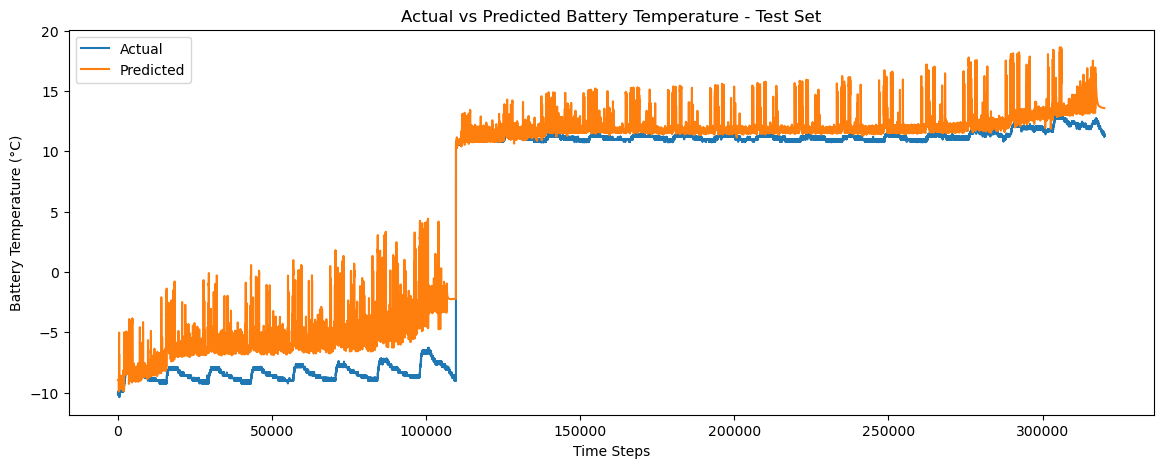

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(y_test_actual, label="Actual")
plt.plot(y_test_pred, label="Predicted")

plt.xlabel("Time Steps")
plt.ylabel("Battery Temperature (°C)")
plt.title("Actual vs Predicted Battery Temperature - Test Set")
plt.legend()
plt.show()

In [45]:
# CNN-LSTM model
model.save("cnn_lstm_battery_temperature.keras")

# Preprocessing scalers
import joblib

joblib.dump(feature_scaler, "feature_scaler.pkl")
joblib.dump(target_scaler, "target_scaler.pkl")

['target_scaler.pkl']

In [46]:
import os

print(os.path.abspath("cnn_lstm_battery_temperature.keras"))

C:\Users\medha\cnn_lstm_battery_temperature.keras
